In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBRegressor

DB_USER = "postgres"
DB_PASSWORD = "zxcZXC#123" 
DB_HOST = "localhost"
DB_PORT = "5432"
DB_NAME = "retail-demand-pricing"   

engine = create_engine(f"postgresql://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:{DB_PORT}/{DB_NAME}")

query = """
SELECT *
FROM retail.fact_demand_features
ORDER BY date, product_id, region;
"""
df = pd.read_sql(query, engine)
df["date"] = pd.to_datetime(df["date"])

In [9]:
numerical_features = [
    "selling_price",
    "competitor_price",
    "discount_pct",
    "promotion_flag",
    "marketing_spend",
    "temperature_c",
    "humidity_pct",
    "inflation_pct",      
    "interest_rate_pct",   
    "consumer_confidence",
    "fuel_price",
    "gdp_growth_pct",      
    "holiday_flag",
    "festival_flag",
    "week",
    "month",
    "quarter",
    "lag_1",
    "lag_2",
    "lag_4",
    "lag_52",
    "roll_mean_4",
    "roll_mean_13"
]

categorical_features = ["category", "channel", "region"]
all_model_features = numerical_features + categorical_features

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features)
    ],
    remainder="passthrough"
)

X = preprocessor.fit_transform(df[all_model_features])
y = df["demand_units"]

xgb = XGBRegressor(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb.fit(X, y)
print("XGBoost Pricing Engine trained successfully!")

XGBoost Pricing Engine trained successfully!


Select Target Product & Generate Candidate Prices

In [10]:
product_id = "P001"
region = "Delhi NCR"

product_data = df[
    (df["product_id"] == product_id) & 
    (df["region"] == region)
].sort_values("date")

latest = product_data.iloc[-1]
current_price = latest["selling_price"]
unit_cost = latest["unit_cost"]

candidate_prices = np.arange(
    current_price * 0.80,
    current_price * 1.21,
    current_price * 0.02
)

print(f"Target Product: {product_id} | Region: {region}")
print(f"Current Price: ₹{current_price:.2f} | Unit Cost: ₹{unit_cost:.2f}")
print(f"Generated {len(candidate_prices)} candidate prices from ₹{candidate_prices.min():.2f} to ₹{candidate_prices.max():.2f}")

Target Product: P001 | Region: Delhi NCR
Current Price: ₹863.20 | Unit Cost: ₹741.33
Generated 21 candidate prices from ₹690.56 to ₹1035.84


Construct Counterfactual Feature Matrix & Predict Demand

In [11]:
pricing_rows = pd.DataFrame({
    "selling_price": candidate_prices,
    "competitor_price": latest["competitor_price"],
    "discount_pct": (
        (latest["list_price"] - candidate_prices) / latest["list_price"] * 100
    ),
    "promotion_flag": latest["promotion_flag"],
    "marketing_spend": latest["marketing_spend"],
    "temperature_c": latest["temperature_c"],
    "humidity_pct": latest["humidity_pct"],
    "inflation_pct": latest["inflation_pct"],          
    "interest_rate_pct": latest["interest_rate_pct"],   
    "consumer_confidence": latest["consumer_confidence"],
    "fuel_price": latest["fuel_price"],
    "gdp_growth_pct": latest["gdp_growth_pct"],         
    "holiday_flag": latest["holiday_flag"],
    "festival_flag": latest["festival_flag"],
    "week": latest["week"],
    "month": latest["month"],
    "quarter": latest["quarter"],
    "lag_1": latest["lag_1"],
    "lag_2": latest["lag_2"],
    "lag_4": latest["lag_4"],
    "lag_52": latest["lag_52"],
    "roll_mean_4": latest["roll_mean_4"],
    "roll_mean_13": latest["roll_mean_13"],
    "category": latest["category"],
    "channel": latest["channel"],
    "region": latest["region"]
})

pricing_encoded = preprocessor.transform(pricing_rows[all_model_features])
pricing_rows["predicted_demand"] = xgb.predict(pricing_encoded)

print("Demand predictions generated for all candidate prices!")
display(pricing_rows[["selling_price", "discount_pct", "predicted_demand"]].head())

Demand predictions generated for all candidate prices!


,selling_price,discount_pct,predicted_demand
0,690.560,24.207569,345.224457
1,707.824,22.312758,335.729858
2,725.088,20.417947,328.360077
3,742.352,18.523136,292.208466
4,759.616,16.628326,290.360626


Unit Economics & Maximum-Profit Optimization

In [12]:
pricing_rows["revenue"] = pricing_rows["selling_price"] * pricing_rows["predicted_demand"]
pricing_rows["profit"] = (pricing_rows["selling_price"] - unit_cost) * pricing_rows["predicted_demand"]

optimal_row = pricing_rows.loc[pricing_rows["profit"].idxmax()]

print("==================================================")
print("            OPTIMAL PRICING RECOMMENDATION        ")
print("==================================================")
print(f"Current Price:          ₹{current_price:.2f}")
print(f"Optimal Price:          ₹{optimal_row['selling_price']:.2f}")
print(f"Predicted Unit Demand: {optimal_row['predicted_demand']:.2f} units")
print(f"Predicted Revenue:     ₹{optimal_row['revenue']:.2f}")
print(f"Maximum Profit:        ₹{optimal_row['profit']:.2f}")
print("==================================================")

            OPTIMAL PRICING RECOMMENDATION        
Current Price:          ₹863.20
Optimal Price:          ₹1035.84
Predicted Unit Demand: 159.45 units
Predicted Revenue:     ₹165165.49
Maximum Profit:        ₹46959.85


Price Optimization & Profit Curve Visualization

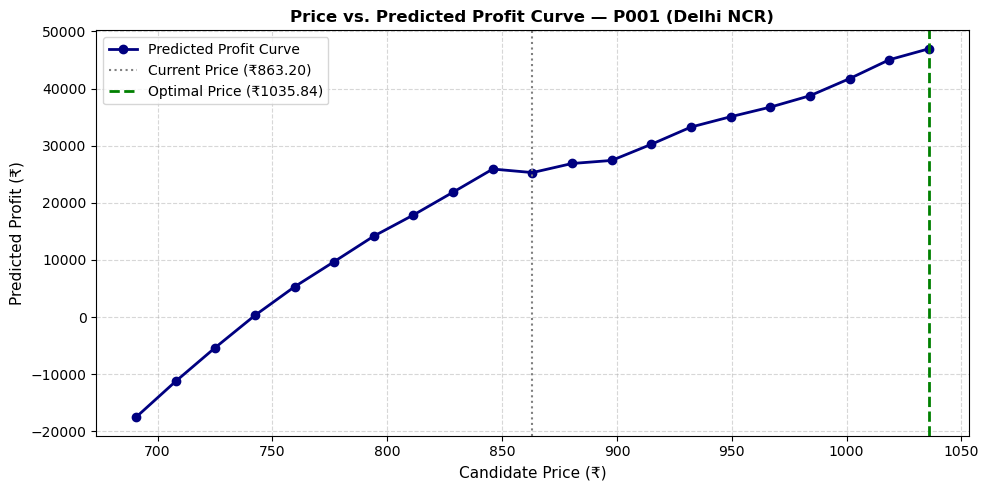

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

plt.plot(
    pricing_rows["selling_price"], 
    pricing_rows["profit"], 
    marker="o", 
    color="navy", 
    linewidth=2, 
    label="Predicted Profit Curve"
)

plt.axvline(
    x=current_price, 
    color="gray", 
    linestyle=":", 
    linewidth=1.5, 
    label=f"Current Price (₹{current_price:.2f})"
)

plt.axvline(
    x=optimal_row["selling_price"], 
    color="green", 
    linestyle="--", 
    linewidth=2, 
    label=f"Optimal Price (₹{optimal_row['selling_price']:.2f})"
)

plt.title(f"Price vs. Predicted Profit Curve — {product_id} ({region})", fontsize=12, fontweight="bold")
plt.xlabel("Candidate Price (₹)", fontsize=11)
plt.ylabel("Predicted Profit (₹)", fontsize=11)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()